# Introduction

I chose to do the police arrests in the city of Pittsburgh from 2016 to 2023. This dataset will allow me to determine which neighborhood has the most arrests occuring in them, which showcases the city with the most responding police units and the most dangerous people (in theory this is what it means, but it may not be related). 


# Sub-Metric

The sub-metric we chose to use was the 'safest' neighborhood. For me to determine this, I will be looking at the neighborhood with the least amount of arrests in the time frame of the data, as well as possibly the neighborhood with the most arrests. showcasing the most responsive neighborhood.

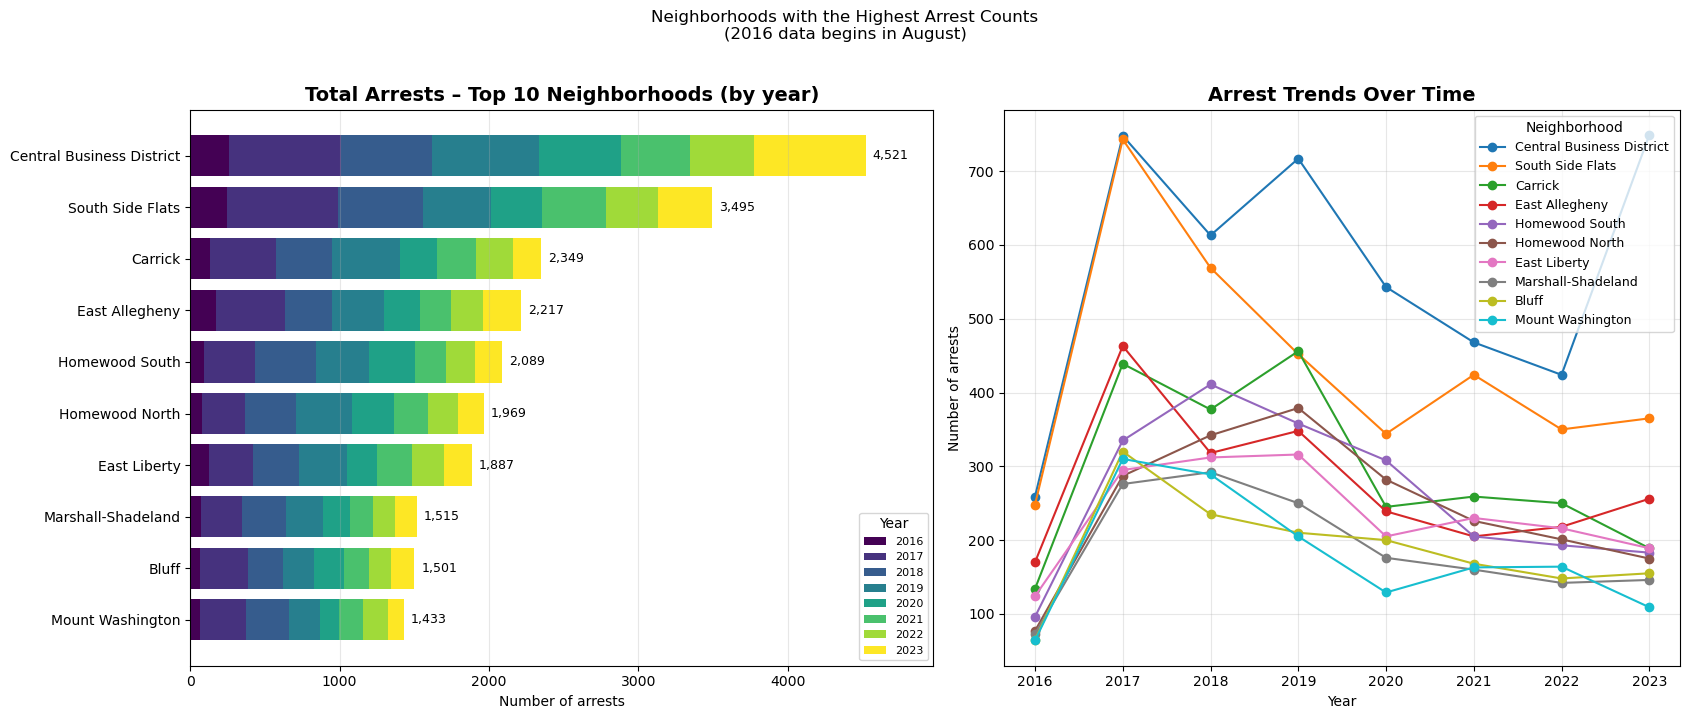

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Crime_Arrests.csv"
TOP_N = 10

#Only loking at the top 10 highest arrest neighborhoods
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
df["ARRESTTIME"] = pd.to_datetime(df["ARRESTTIME"], errors="coerce")
df["year"] = df["ARRESTTIME"].dt.year
df = df.dropna(subset=["INCIDENTNEIGHBORHOOD", "year"])
df["year"] = df["year"].astype(int)
df = df[df["year"] >= 2016]

#Reduce to Pittsburgh's 90 official neighborhoods
merge = {
    "Central North Side": "Central Northside",
    "Golden Triangle/Civic Arena": "Central Business District",
    "Troy Hill-Herrs Island": "Troy Hill",
    "Mt. Oliver Neighborhood": "Mount Oliver",
}
df["neighborhood"] = df["INCIDENTNEIGHBORHOOD"].replace(merge)
drop = ["Outside City", "Outside County", "Outside State", "Mt. Oliver Boro"]
df = df[~df["neighborhood"].isin(drop)]

#Aggregate: keep the 10 neighborhoods with the most arrests
counts = df.groupby(["neighborhood", "year"]).size().unstack(fill_value=0)
top = counts.sum(axis=1).nlargest(TOP_N).index
top_counts = counts.loc[top]                #ordered highest to lowest

#Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7),
                               gridspec_kw={"width_ratios": [1.1, 1]})

#Stacked horizontal bar chart (total per neighborhood, split by year)
years = list(top_counts.columns)
year_colors = plt.cm.viridis(np.linspace(0, 1, len(years)))
plot_counts = top_counts.iloc[::-1]          #highest neighborhood on top
left = np.zeros(len(plot_counts))
for yr, c in zip(years, year_colors):
    ax1.barh(plot_counts.index, plot_counts[yr], left=left, color=c, label=str(yr))
    left += plot_counts[yr].values
for y, total in enumerate(left):
    ax1.text(total + left.max() * 0.01, y, f"{int(total):,}", va="center", fontsize=9)
ax1.set_xlim(0, left.max() * 1.1)
ax1.set_title(f"Total Arrests – Top {TOP_N} Neighborhoods (by year)",
              fontsize=14, weight="bold")
ax1.set_xlabel("Number of arrests")
ax1.grid(axis="x", alpha=0.3)
ax1.legend(title="Year", fontsize=8, loc="lower right")

#Line chart
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for k, name in enumerate(top_counts.index):
    ax2.plot(top_counts.columns, top_counts.loc[name], marker="o",
             label=name, color=colors[k % 10])
ax2.set_title("Arrest Trends Over Time", fontsize=14, weight="bold")
ax2.set_xlabel("Year")
ax2.set_ylabel("Number of arrests")
ax2.set_xticks(list(top_counts.columns))
ax2.grid(True, alpha=0.3)
ax2.legend(title="Neighborhood", fontsize=9, loc="upper right")

fig.suptitle("Neighborhoods with the Highest Arrest Counts\n"
             "(2016 data begins in August)",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

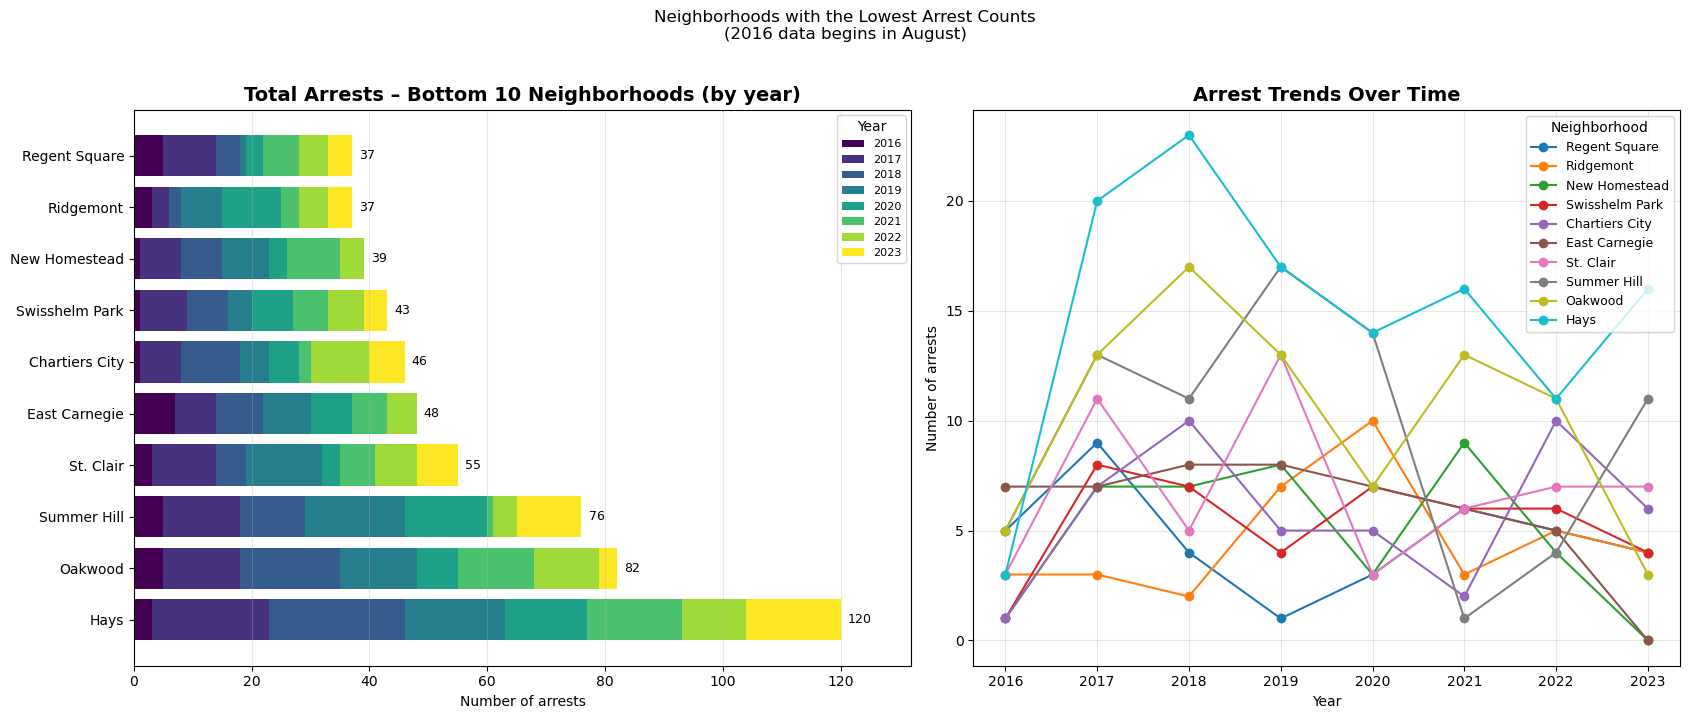

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Crime_Arrests.csv"
BOTTOM_N = 10

#Taking bottom 10 arrest neighborhoods
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
df["ARRESTTIME"] = pd.to_datetime(df["ARRESTTIME"], errors="coerce")
df["year"] = df["ARRESTTIME"].dt.year
df = df.dropna(subset=["INCIDENTNEIGHBORHOOD", "year"])
df["year"] = df["year"].astype(int)
df = df[df["year"] >= 2016]

#Reduce to Pittsburgh's 90 official neighborhoods
merge = {
    "Central North Side": "Central Northside",
    "Golden Triangle/Civic Arena": "Central Business District",
    "Troy Hill-Herrs Island": "Troy Hill",
    "Mt. Oliver Neighborhood": "Mount Oliver",
}
df["neighborhood"] = df["INCIDENTNEIGHBORHOOD"].replace(merge)
drop = ["Outside City", "Outside County", "Outside State", "Mt. Oliver Boro"]
df = df[~df["neighborhood"].isin(drop)]

#Aggregate: keep the 10 neighborhoods with the least arrests
counts = df.groupby(["neighborhood", "year"]).size().unstack(fill_value=0)
bottom = counts.sum(axis=1).nsmallest(BOTTOM_N).index
bottom_counts = counts.loc[bottom]          #ordered lowest to highest

#Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7),
                               gridspec_kw={"width_ratios": [1.1, 1]})

#Stacked horizontal bar chart (total per neighborhood, split by year)
years = list(bottom_counts.columns)
year_colors = plt.cm.viridis(np.linspace(0, 1, len(years)))
plot_counts = bottom_counts.iloc[::-1]       #highest of the bottom 10 on top
left = np.zeros(len(plot_counts))
for yr, c in zip(years, year_colors):
    ax1.barh(plot_counts.index, plot_counts[yr], left=left, color=c, label=str(yr))
    left += plot_counts[yr].values
for y, total in enumerate(left):
    ax1.text(total + left.max() * 0.01, y, f"{int(total):,}", va="center", fontsize=9)
ax1.set_xlim(0, left.max() * 1.1)
ax1.set_title(f"Total Arrests – Bottom {BOTTOM_N} Neighborhoods (by year)",
              fontsize=14, weight="bold")
ax1.set_xlabel("Number of arrests")
ax1.grid(axis="x", alpha=0.3)
ax1.legend(title="Year", fontsize=8, loc="upper right")

#Line chart
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for k, name in enumerate(bottom_counts.index):
    ax2.plot(bottom_counts.columns, bottom_counts.loc[name], marker="o",
             label=name, color=colors[k % 10])
ax2.set_title("Arrest Trends Over Time", fontsize=14, weight="bold")
ax2.set_xlabel("Year")
ax2.set_ylabel("Number of arrests")
ax2.set_xticks(list(bottom_counts.columns))
ax2.grid(True, alpha=0.3)
ax2.legend(title="Neighborhood", fontsize=9, loc="upper right")

fig.suptitle("Neighborhoods with the Lowest Arrest Counts\n"
             "(2016 data begins in August)",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

90 neighborhoods, 63,486 arrests


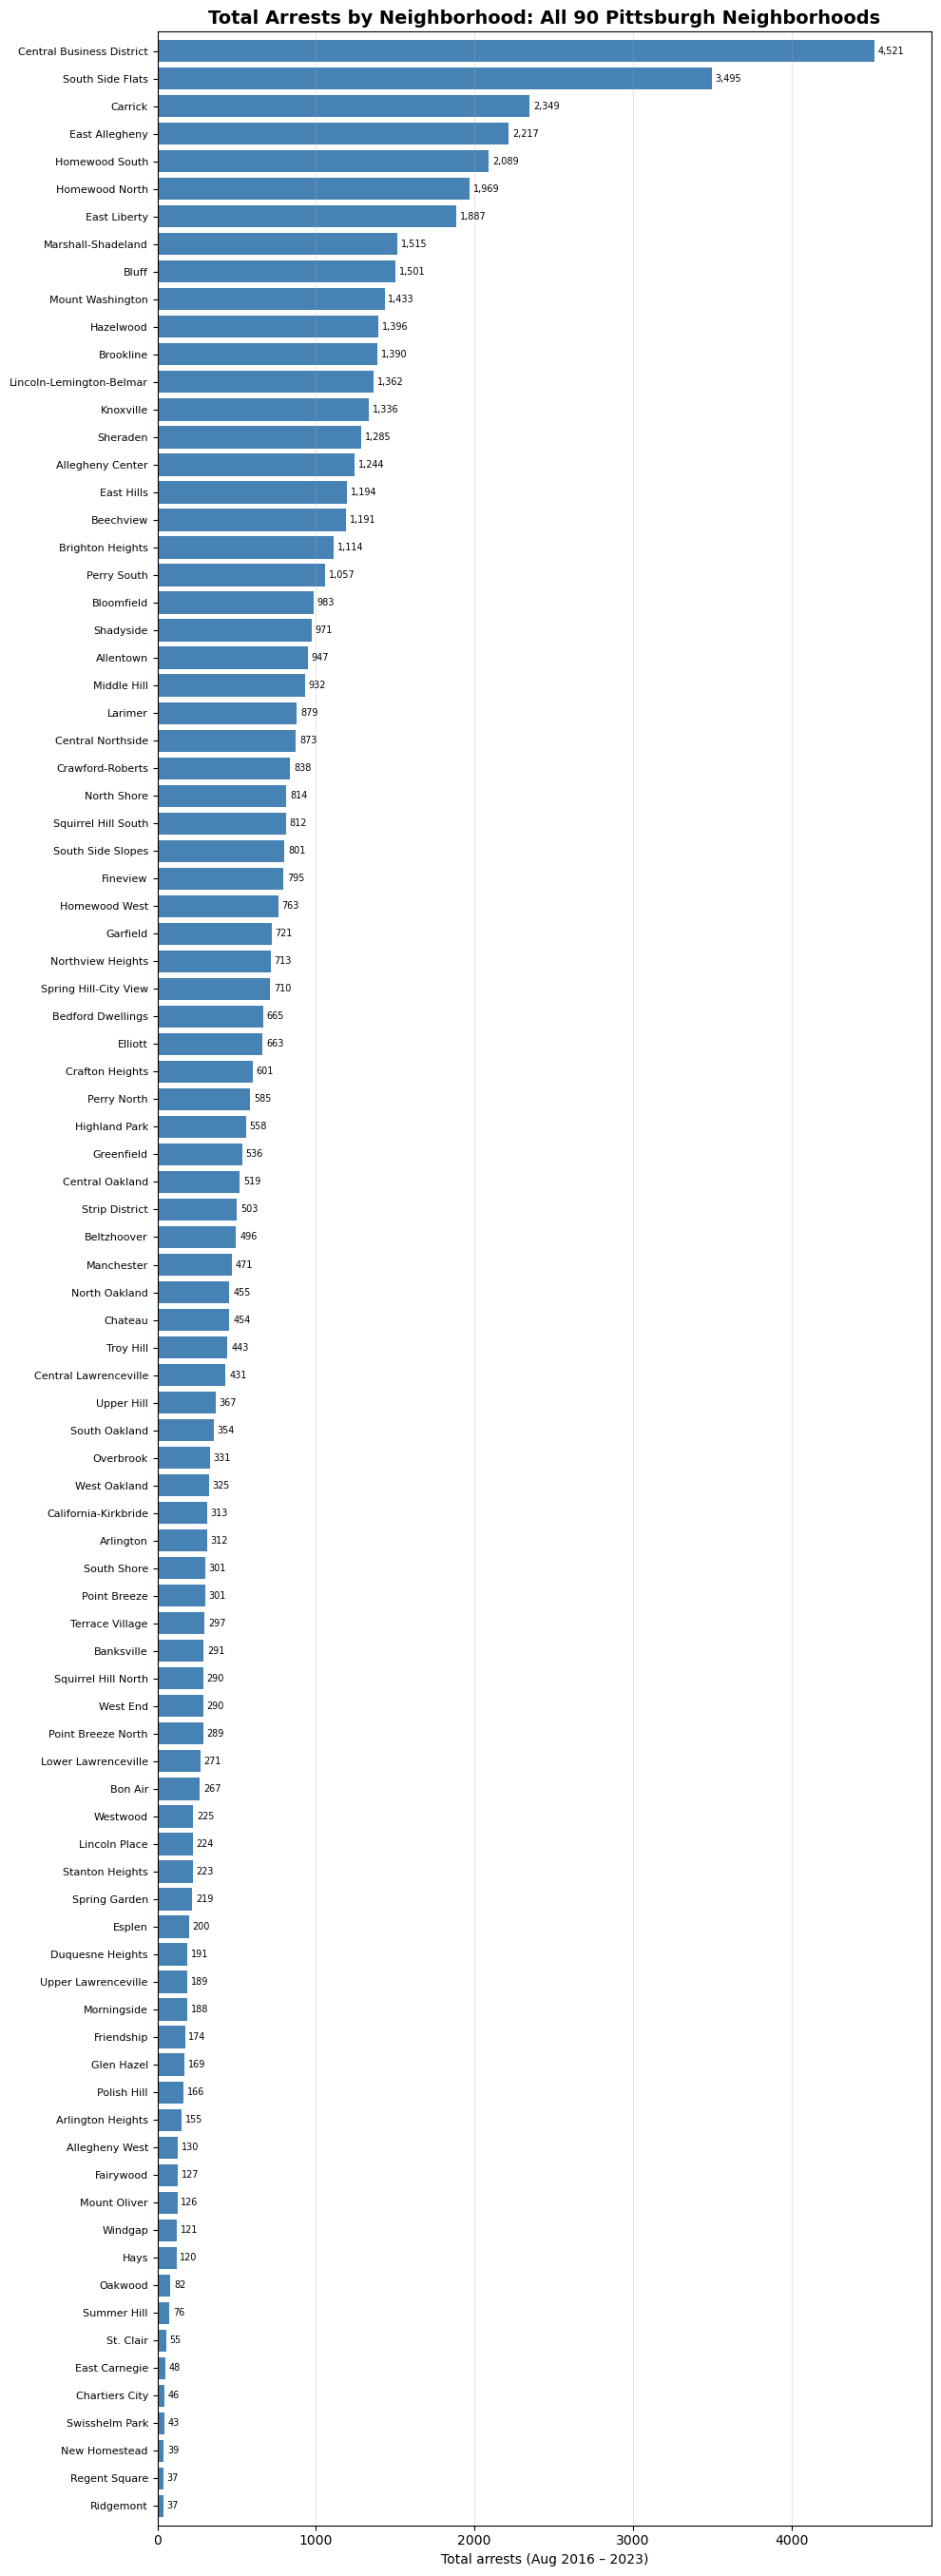

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "Crime_Arrests.csv"

# Load & clean
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
df["ARRESTTIME"] = pd.to_datetime(df["ARRESTTIME"], errors="coerce")
df["year"] = df["ARRESTTIME"].dt.year
df = df.dropna(subset=["INCIDENTNEIGHBORHOOD", "year"])
df["year"] = df["year"].astype(int)
df = df[df["year"] >= 2016]

#This is combining areas into distinct neighborhoods so only 90 are represented,
#not the 98 included in the file.
merge = {
    "Central North Side": "Central Northside",
    "Golden Triangle/Civic Arena": "Central Business District",
    "Troy Hill-Herrs Island": "Troy Hill",
    "Mt. Oliver Neighborhood": "Mount Oliver",
}
df["neighborhood"] = df["INCIDENTNEIGHBORHOOD"].replace(merge)

#Drop labels that are not Pittsburgh neighborhoods
drop = ["Outside City", "Outside County", "Outside State", "Mt. Oliver Boro"]
df = df[~df["neighborhood"].isin(drop)]

totals = df["neighborhood"].value_counts()
print(f"{len(totals)} neighborhoods, {totals.sum():,} arrests")
assert len(totals) == 90

#Plot all 90, highest to lowest, top to bottom
plot_totals = totals.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 0.28 * len(plot_totals) + 2))
ax.barh(plot_totals.index, plot_totals.values, color="steelblue")
for y, v in enumerate(plot_totals.values):
    ax.text(v + totals.max() * 0.005, y, f"{v:,}", va="center", fontsize=7)
ax.set_xlim(0, totals.max() * 1.08)
ax.set_ylim(-0.7, len(plot_totals) - 0.3)
ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("Total arrests (Aug 2016 – 2023)")
ax.set_title("Total Arrests by Neighborhood: All 90 Pittsburgh Neighborhoods",
             fontsize=14, weight="bold")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Explanation
After looking at these graphs, it shows us a clear and easy to see visualization of the data.